# Load Data

In [1]:
from google.colab import drive

drive.mount('/content/data')

Drive already mounted at /content/data; to attempt to forcibly remount, call drive.mount("/content/data", force_remount=True).


In [2]:
import easydict

args = easydict.EasyDict()
args.pizza_steak_sushi_path = "/content/data/MyDrive/colab tutorial/data/pizza_steak_sushi"
args.train_path = args.pizza_steak_sushi_path + "/train"
args.test_path = args.pizza_steak_sushi_path + "/test"

In [3]:
from pathlib import Path

train_path = Path(args.train_path)
test_path = Path(args.test_path)

train_path, test_path

(PosixPath('/content/data/MyDrive/colab tutorial/data/pizza_steak_sushi/train'),
 PosixPath('/content/data/MyDrive/colab tutorial/data/pizza_steak_sushi/test'))

In [4]:
len(
    list(train_path.glob("*/*.jpg"))
)

225

In [5]:
len(
    list(test_path.glob("*/*.jpg"))
)

75

In [6]:
import random
from PIL import Image

random_img_path = random.choice(list(train_path.glob("*/*.jpg")))
random_img_path

PosixPath('/content/data/MyDrive/colab tutorial/data/pizza_steak_sushi/train/steak/2707522.jpg')

In [7]:
label = random_img_path.parent.stem
label

'steak'

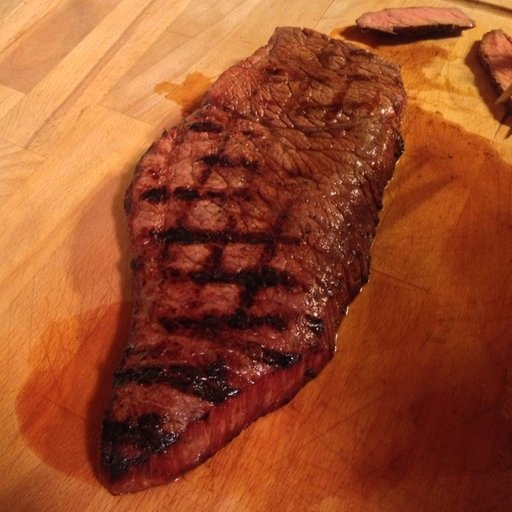

In [8]:
img = Image.open(random_img_path)
img

# Create Dataset

In [9]:
from torchvision import datasets
from torchvision import transforms as T

# feature.shape => (color=3, row=200, column=200)
train_data = datasets.ImageFolder(
    root=train_path,
    transform=T.Compose([
        T.RandAugment(), # tensor 8bit만 인식 가능!
        T.ToTensor(), # float32 bit로 변환
        T.RandomCrop(size=(200, 200)),
        # T.Normalize(mean=color_means, std=color_stds),
    ])
)
# feature.shape => (color=3, row=200, column=200)
test_data = datasets.ImageFolder(
    root=test_path,
    transform=T.Compose([
        T.ToTensor(),
        T.Resize((200, 200)),
        # T.Normalize(mean=color_means, std=color_stds),
    ])
)

len(train_data), len(test_data)

(225, 75)

In [10]:
feature, target = train_data[1]

feature.shape, target

(torch.Size([3, 200, 200]), 0)

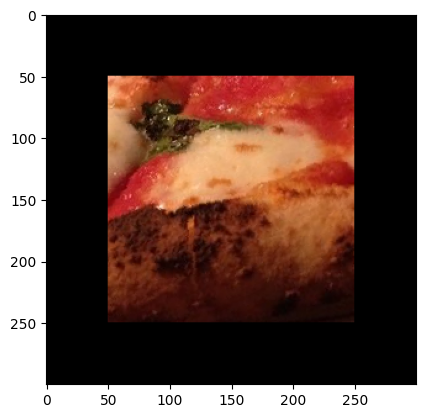

In [11]:
import matplotlib.pyplot as plt
import numpy as np

tmp = T.Pad(padding=50)(feature)

plt.imshow(tmp.permute(1,2,0).numpy())
plt.show()

# Create DataLoader

In [12]:
from torch.utils.data import DataLoader

BATCH_SIZE = 10

train_dataloader = DataLoader(
    dataset=train_data, batch_size=BATCH_SIZE, shuffle=True)
test_dataloader = DataLoader(
    dataset=test_data, batch_size=BATCH_SIZE, shuffle=False)

len(train_dataloader), len(test_dataloader)

(23, 8)

In [13]:
features, targets = next(iter(train_dataloader))

# features.shape => (batch, color, row, column)
features.shape, targets.shape

(torch.Size([10, 3, 200, 200]), torch.Size([10]))

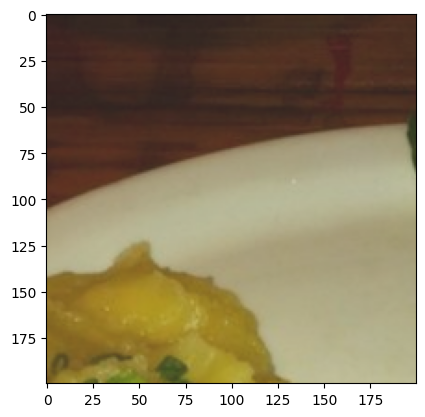

In [14]:
plt.imshow(features[0].permute(1,2,0).numpy())
plt.show()

# Normalize 적용
이미지의 각 색상 채널을 다음처럼 표준화합니다.


### Normalize를 사용하는 핵심 이유는 다음과 같습니다.
- 학습을 안정적으로 만듭니다. 입력값의 크기와 분포가 일정해져서 gradient가 지나치게 크거나 작아지는 현상이 줄어듭니다.
- 학습 속도가 빨라집니다. 입력 데이터가 대체로 평균 0, 표준편차 1에 가까워져 optimizer가 손실 함수의 최적점을 찾기 쉬워집니다.
- 채널 간 차이를 보정합니다. 특정 색상 채널의 값이 크다는 이유만으로 모델에 더 큰 영향을 주는 것을 방지합니다.
- 사전 학습 모델의 입력 조건을 맞춥니다. ImageNet으로 학습된 모델은 보통 ImageNet의 평균과 표준편차로 정규화된 이미지를 기대합니다.

### Calculate Normalize

In [15]:
import torch
from torchvision.io import read_image

def calculate_norm(data_paths, glob_str="*/*.jpg"):

  lst_tensors = [
    read_image(img_path) for img_path in list(data_paths.glob(glob_str))
  ]

  map_means = np.array([
      tensors.numpy().mean(axis=(1,2)) for tensors in lst_tensors
  ])
  map_stds = np.array([
      tensors.numpy().std(axis=(1,2)) for tensors in lst_tensors
  ])
  # RGB의 평균 & 표준편차
  return map_means.mean(axis=0), map_stds.mean(axis=0)

In [16]:
color_means, color_stds = calculate_norm(train_path)
color_means, color_stds

(array([136.52950362, 106.4688683 ,  84.17607196]),
 array([61.6535061 , 62.50642597, 59.99324794]))

### Create Dataset

In [17]:
from torchvision import datasets
from torchvision import transforms as T

# feature.shape => (color=3, row=200, column=200)
train_data = datasets.ImageFolder(
    root=train_path,
    transform=T.Compose([
        T.RandAugment(), # tensor 8bit만 인식 가능!
        T.ToTensor(), # float32 bit로 변환
        T.RandomCrop(size=(200, 200)),
        T.Normalize(mean=color_means, std=color_stds),
    ])
)
# feature.shape => (color=3, row=200, column=200)
test_data = datasets.ImageFolder(
    root=test_path,
    transform=T.Compose([
        T.ToTensor(),
        T.Resize((200, 200)),
        T.Normalize(mean=color_means, std=color_stds),
    ])
)

len(train_data), len(test_data)

(225, 75)

In [18]:
feature, target = train_data[1]

feature.shape, target

(torch.Size([3, 200, 200]), 0)

### Create DataLoader

In [19]:
from torch.utils.data import DataLoader

BATCH_SIZE = 10

train_dataloader = DataLoader(
    dataset=train_data, batch_size=BATCH_SIZE, shuffle=True)
test_dataloader = DataLoader(
    dataset=test_data, batch_size=BATCH_SIZE, shuffle=False)

len(train_dataloader), len(test_dataloader)

(23, 8)

In [20]:
features, targets = next(iter(train_dataloader))

# features.shape => (batch, color, row, column)
features.shape, targets.shape

(torch.Size([10, 3, 200, 200]), torch.Size([10]))